# Gradient Importance Analysis

This notebook analyzes the output files from the gradient importance analysis to answer:
- Are free dimensions more important than forced (concept) dimensions?
- Which concepts are most important for each class?

Visualizations are included where helpful.

In [2]:
# 1. Import Required Libraries
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict

# Set up matplotlib for inline display
%matplotlib inline

In [3]:
# 2. Load and Parse Output Files
output_dir = os.path.dirname(os.path.abspath("./gradient_importance_analysis_combined.json"))
output_file = os.path.join(output_dir, "gradient_importance_analysis_combined.json")

# Load concepts
concepts_path = os.path.join(output_dir, "imparting-interpretability", "concepts.txt")
with open(concepts_path, "r") as f:
    concepts = [line.strip() for line in f if line.strip()]
num_forced = len(concepts)
num_total = num_forced * 2  # assumes 100 forced + 100 free

# Load combined results: {class: {mean_importance, dimension_ranking}}
with open(output_file, "r") as f:
    results = json.load(f)

# Parse into DataFrame: one row per (class, dimension)
rows = []
for class_name, class_info in results.items():
    for rank in class_info["dimension_ranking"]:
        dim_idx = rank["dimension"]
        is_forced = (dim_idx < num_forced)
        is_free = (dim_idx >= num_total - num_forced)
        rows.append({
            "class": class_name,
            "dimension": dim_idx,
            "concept": rank["concept"] if is_forced else "",
            "mean_importance": rank["mean_importance"],
            "mean_abs_importance": rank["mean_abs_importance"],
            "is_forced": is_forced,
            "is_free": is_free,
        })
df = pd.DataFrame(rows)
df.head()

,class,dimension,concept,mean_importance,mean_abs_importance,is_forced,is_free
0,Normal,68,Recklessness,0.424392,0.424392,True,False
1,Normal,172,,0.357222,0.357222,False,True
2,Normal,50,Avoidance,0.305611,0.305611,True,False
3,Normal,102,,0.265982,0.265982,False,True
4,Normal,194,,0.249197,0.249197,False,True


In [4]:
# 3. Aggregate Importance Scores by Dimension Type
# Group by class and is_forced (forced/concept vs free)
aggs = df.groupby(["class", "is_forced"]).agg(
    mean_importance_mean=("mean_importance", "mean"),
    mean_abs_importance_mean=("mean_abs_importance", "mean"),
    count=("dimension", "count")
).reset_index()
aggs.head()


,class,is_forced,mean_importance_mean,mean_abs_importance_mean,count
0,Anxiety,False,0.052407,0.060267,101
1,Anxiety,True,0.022958,0.053122,99
2,Bipolar,False,0.051265,0.071593,101
3,Bipolar,True,0.020489,0.054987,99
4,Depression,False,0.040481,0.047209,101


Mean abs importance (forced): 0.0539
Mean abs importance (free):   0.0595
t-test: t=-1.27, p=0.203


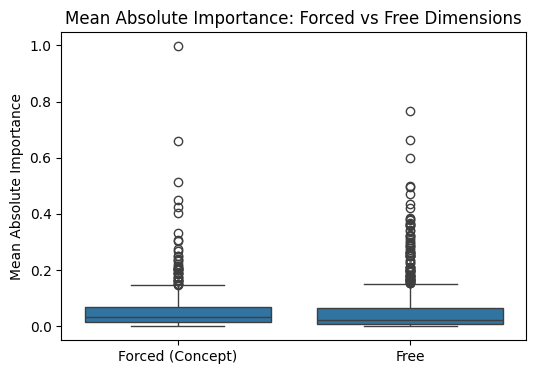

In [5]:
# 4. Compare Importance: Free vs Forced Dimensions
from scipy.stats import ttest_ind

# Compare mean absolute importance for forced vs free dimensions (all splits/classes)
forced = df[df["is_forced"]]["mean_abs_importance"]
free = df[~df["is_forced"]]["mean_abs_importance"]

mean_forced = forced.mean()
mean_free = free.mean()
t_stat, p_val = ttest_ind(forced, free, equal_var=False)

print(f"Mean abs importance (forced): {mean_forced:.4f}")
print(f"Mean abs importance (free):   {mean_free:.4f}")
print(f"t-test: t={t_stat:.2f}, p={p_val:.3g}")

# Boxplot visualization
plt.figure(figsize=(6,4))
sns.boxplot(x=df["is_forced"].map({True: "Forced (Concept)", False: "Free"}), y=df["mean_abs_importance"])
plt.title("Mean Absolute Importance: Forced vs Free Dimensions")
plt.ylabel("Mean Absolute Importance")
plt.xlabel("")
plt.show()

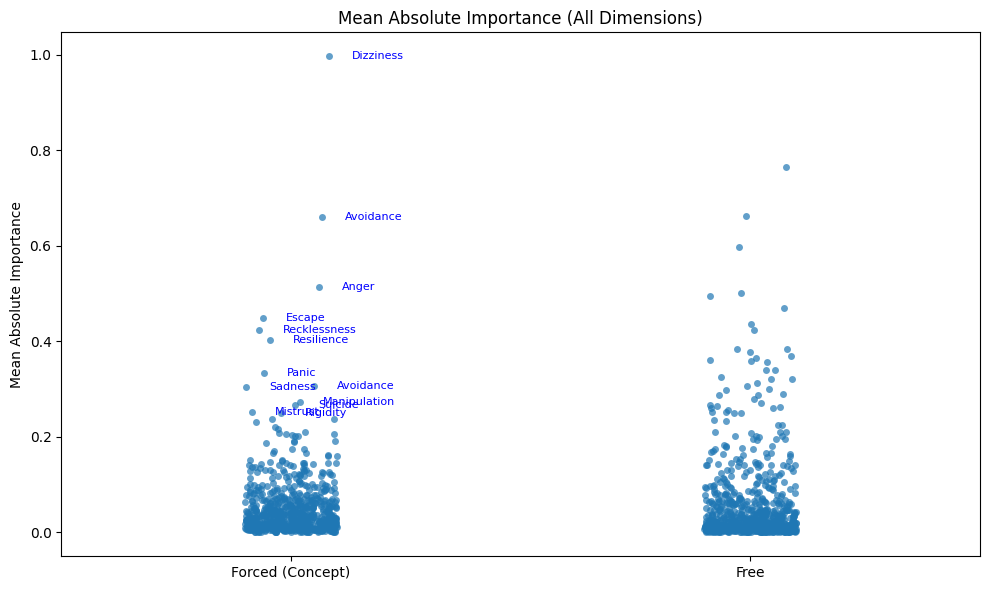

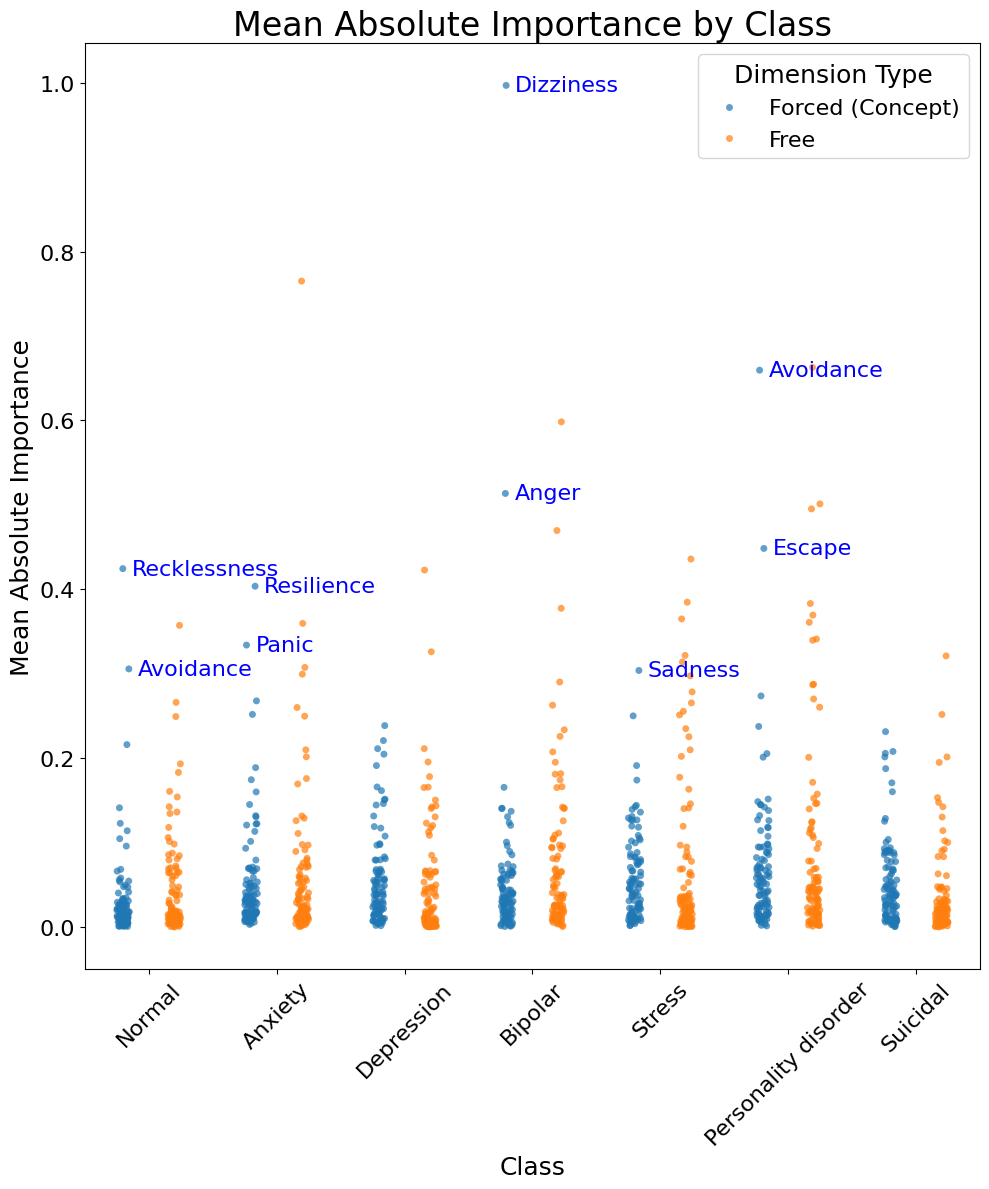

In [10]:
# Visualize the distribution of raw importance values for all dimensions (per-class) with labels only for forced outliers, placed next to their points
plt.figure(figsize=(10,6))
ax = sns.stripplot(x=df["is_forced"].map({True: "Forced (Concept)", False: "Free"}), y=df["mean_abs_importance"], jitter=True, alpha=0.7)
plt.title("Mean Absolute Importance (All Dimensions)")
plt.ylabel("Mean Absolute Importance")
plt.xlabel("")
# Get the actual x positions of the points for accurate label placement
for i, row in df.iterrows():
    if row["is_forced"] and row["mean_abs_importance"] > 0.25:
        x_val = 0 if row["is_forced"] else 1
        y_vals = df[df["is_forced"] == row["is_forced"]]["mean_abs_importance"].values
        idx = (y_vals == row["mean_abs_importance"]).nonzero()[0]
        points = ax.collections[x_val].get_offsets()
        if len(idx) > 0 and len(points) > idx[0]:
            x_plot, y_plot = points[idx[0]]
            ax.text(x_plot + 0.05, y_plot, row["concept"], fontsize=8, color='blue', ha='left', va='center', rotation=0)
plt.tight_layout()
plt.show()

# To see the distribution per class as well:
plt.figure(figsize=(10,12))
ax2 = sns.stripplot(x=df["class"], y=df["mean_abs_importance"], hue=df["is_forced"].map({True: "Forced (Concept)", False: "Free"}), dodge=True, jitter=True, alpha=0.7)
plt.title("Mean Absolute Importance by Class", fontsize=24)
plt.ylabel("Mean Absolute Importance", fontsize=18)
plt.xlabel("Class", fontsize=18)
plt.xticks(fontsize=16, rotation=45)
plt.yticks(fontsize=16)
plt.legend(title="Dimension Type", fontsize=16, title_fontsize=18)
# Place labels next to their actual points for forced outliers > 0.20
class_list = list(df["class"].unique())
for i, row in df.iterrows():
    if row["is_forced"] and row["mean_abs_importance"] > 0.3:
        x_val = class_list.index(row["class"])
        y_vals = df[(df["class"] == row["class"]) & (df["is_forced"] == row["is_forced"])]["mean_abs_importance"].values
        idx = (y_vals == row["mean_abs_importance"]).nonzero()[0]
        col_idx = x_val * 2 + (0 if row["is_forced"] else 1)
        if col_idx < len(ax2.collections):
            points = ax2.collections[col_idx].get_offsets()
            if len(idx) > 0 and len(points) > idx[0]:
                x_plot, y_plot = points[idx[0]]
                ax2.text(x_plot + 0.07, y_plot, row["concept"], fontsize=16, color='blue', ha='left', va='center', rotation=0)
plt.tight_layout()
plt.show()

In [25]:
# 5. Identify Most Important Concepts per Class
# For each class, get the top 5 most important forced (concept) dimensions
most_important = {}
for class_name in df["class"].unique():
    class_df = df[(df["class"] == class_name) & (df["is_forced"])]
    top = class_df.sort_values("mean_abs_importance", ascending=False).head(5)
    most_important[class_name] = list(zip(top["concept"], top["mean_abs_importance"]))

# Display as a table
pd.DataFrame({k: [x[0] for x in v] for k, v in most_important.items()})

,Normal,Anxiety,Depression,Bipolar,Stress,Personality disorder,Suicidal
0,Recklessness,dim_182,dim_108,Dizziness,dim_135,dim_153,dim_108
1,dim_172,Resilience,dim_178,dim_107,dim_120,Avoidance,dim_105
2,Avoidance,dim_129,Grief,Anger,dim_168,dim_103,Concentration
3,dim_102,Panic,Instability,dim_132,dim_167,dim_146,Emptiness
4,dim_194,dim_101,dim_157,dim_109,dim_183,Escape,Fatigue


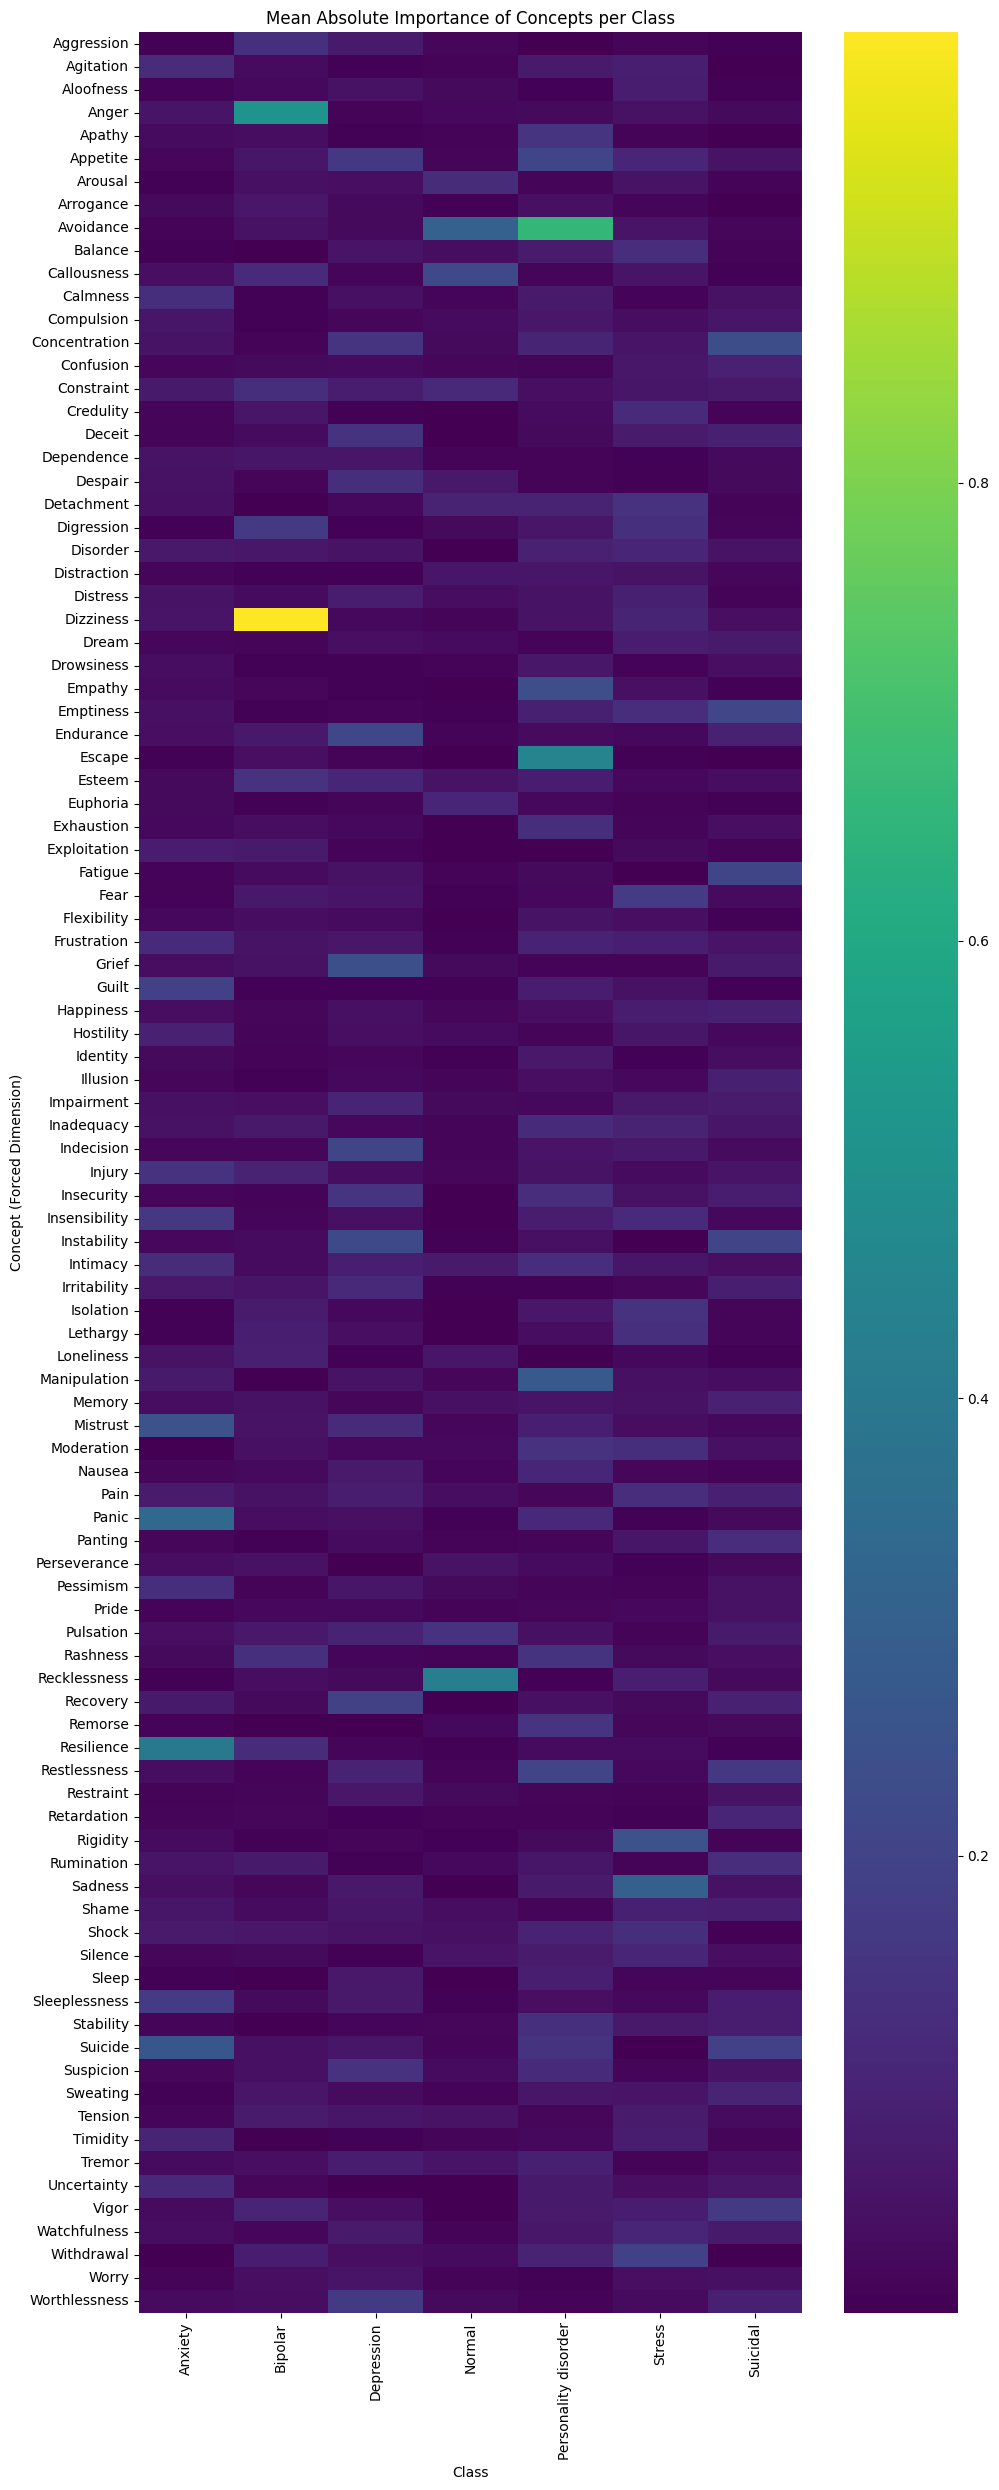

In [77]:
# 6. Visualize Importance Distributions with Matplotlib
# Heatmap: concepts (forced dims) vs class, colored by mean_abs_importance
pivot = df[df["is_forced"]].pivot_table(
    index="concept", columns="class", values="mean_abs_importance", aggfunc="mean"
)
plt.figure(figsize=(10, max(6, 0.25*len(concepts))))
sns.heatmap(pivot, cmap="viridis", annot=False)
plt.title("Mean Absolute Importance of Concepts per Class")
plt.xlabel("Class")
plt.ylabel("Concept (Forced Dimension)")
plt.tight_layout()
plt.show()